# Food-101 by AND0153

[Food-101 dataset on Kaggle](https://www.kaggle.com/datasets/ranitsarkar01/the-food-101-data-set)

## Install required dependencies

In [2]:
%pip install -q kagglehub matplotlib pillow


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from collections import Counter
from pathlib import Path
import random

import kagglehub
import matplotlib.pyplot as plt
from PIL import Image

/Users/andrys/code/vsb/ML/Food101/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Download the dataset

`kagglehub` returns the local directory containing the downloaded dataset.

In [4]:
dataset_path = Path(kagglehub.dataset_download('ranitsarkar01/the-food-101-data-set'))
print(f"Dataset location: {dataset_path}")

100%|██████████| 4.66G/4.66G [03:30<00:00, 23.8MB/s]

Extracting files...


Dataset location: /Users/andrys/.cache/kagglehub/datasets/ranitsarkar01/the-food-101-data-set/versions/1


In [5]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png'}

def find_image_records(root):
    """Find image paths recursively; the immediate parent is the class."""
    return [
        (path, path.parent.name)
        for path in sorted(Path(root).rglob('*'))
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

image_records = find_image_records(dataset_path)
print(f"Found {len(image_records):,} images in {len(set(label for _, label in image_records)):,} classes.")

Found 101,000 images in 101 classes.


In [11]:
class_counts = Counter(label for _, label in image_records)
print('Images per class (first 10 alphabetically):')
for class_name, count in sorted(class_counts.items())[:10]:
    print(f"  {class_name}: {count:,}")

Images per class (first 10 alphabetically):
  apple_pie: 1,000
  baby_back_ribs: 1,000
  baklava: 1,000
  beef_carpaccio: 1,000
  beef_tartare: 1,000
  beet_salad: 1,000
  beignets: 1,000
  bibimbap: 1,000
  bread_pudding: 1,000
  breakfast_burrito: 1,000


## A reproducible 3 × 3 sample

Class names are made easier to read for the plot labels.

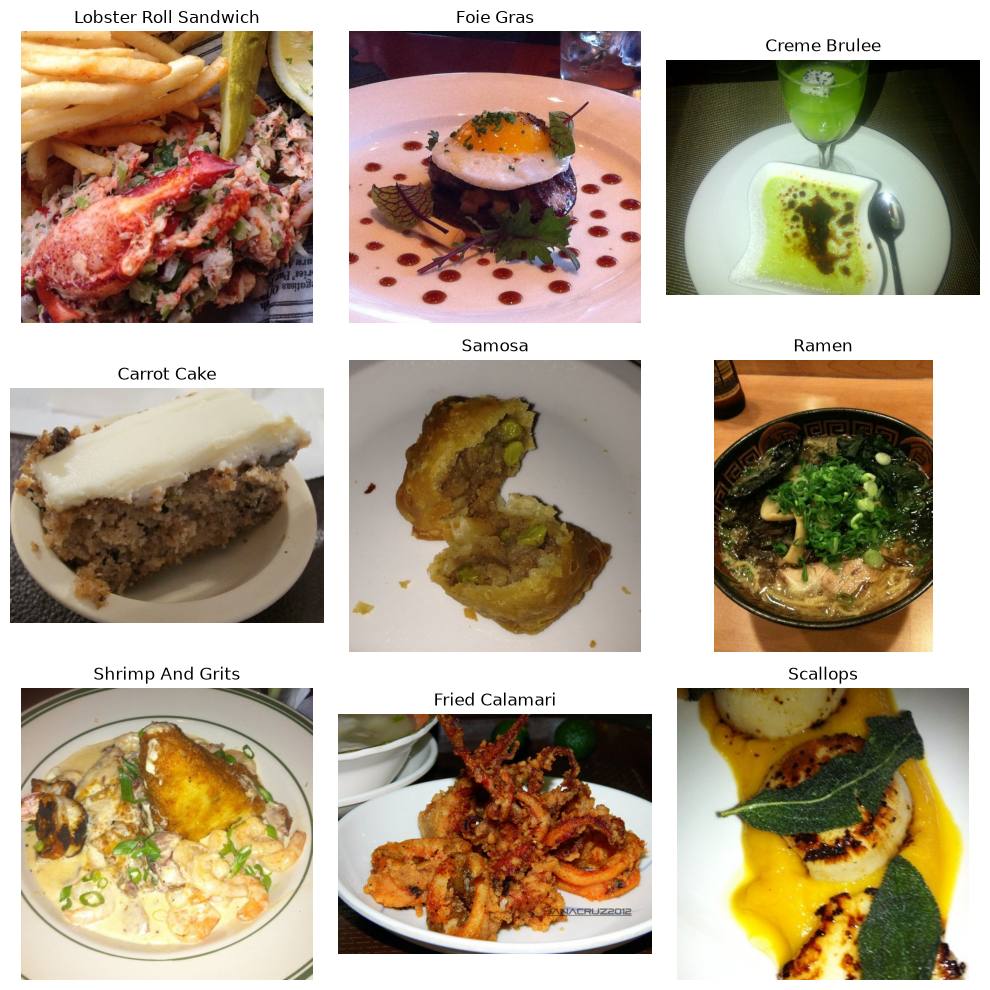

In [16]:
sample = random.sample(image_records, min(9, len(image_records)))
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.ravel()

for axis, (image_path, class_name) in zip(axes, sample):
    with Image.open(image_path) as image:
        axis.imshow(image.convert('RGB'))
    readable_name = class_name.replace('_', ' ').replace('-', ' ').title()
    axis.set_title(readable_name)
    axis.axis('off')

for axis in axes[len(sample):]:
    axis.axis('off')

plt.tight_layout()
plt.show()